> **Modelo D5 (no el final).** Este notebook se ejecutó con `d5_ema_w32_e60_s42.pth`, el candidato de la primera evaluación en test y sin orientación canónica. Sirvió para encontrar el problema de orientación que llevó a H6 (`docs/decisiones_semana10.md`, secciones 12.4 a 12.6). Las cifras del modelo final H6 están en `notebooks/04_semana10_pipeline_multitarea.ipynb` y en `MODEL_CARD.md`.

# 05 · Casos difíciles: mirar, medir y probar qué pasa si se reorientan

**Para qué sirve.** En la evaluación de test el Dice de instancias quedó en 0.845 (objetivo 0.85).
Trece de los quince casos de test están entre 0.825 y 0.926; los casos **012** (0.692) y **039**
(0.710) arrastran el promedio. Este notebook permite verlos corte a corte junto a los dos peores
de validación (**087** y **078**) y probar reorientaciones.

**Regla.** Los casos 012 y 039 son de test: aquí se abren solo para entender el fallo. Las
decisiones (qué modelo, qué preprocesamiento) se toman con validación; ver
`docs/decisiones_semana10.md`, sección 12.

**Qué necesita.** PyTorch, el checkpoint y los datos. Corre en dos sitios sin tocar nada:

- **Colab** (recomendado, con GPU): usa el código de `/content/codigo` y el caché de `/content/datos`.
  Cada caso tarda unos segundos.
- **Local**: usa `outputs/s10/` y `data/raw/`; la primera vez construye el caché de cada caso.
  En CPU cada caso tarda de 1 a 4 minutos.

Colores en todas las figuras: **azul** sacro, **rojo** coxal izquierdo, **verde** coxal derecho;
los fragmentos secundarios salen en otros tonos.

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path
import torch

# Funciona en el repo local y en Colab (código en /content/codigo, caché en /content/datos).
candidatos = [Path.cwd(), *Path.cwd().parents, Path("/content/codigo")]
ROOT = next(p for p in candidatos if (p / "src" / "casos_dificiles.py").exists())
os.chdir(ROOT)                      # las rutas de data/raw son relativas a la raíz del repo
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import casos_dificiles as cd
from orientacion import LPI_CASES, to_canonical

CACHE_ROOT = next((p for p in (Path("/content/datos"), ROOT / "data/cache/s10") if (p / "cache_384").exists()),
                  ROOT / "data/cache/s10")          # si no existe, se construye desde data/raw
CHECKPOINT = next(p for p in (ROOT / "outputs/s10/d5_ema_w32_e60_s42.pth",
                              Path("/content/d5/d5_ema_w32_e60_s42.pth")) if p.exists())   # modelo congelado de la semana 10
CASOS = ["012", "039", "087", "078"]                 # 012 y 039: test (solo diagnóstico); 087 y 078: validación
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

modelo, device = cd.cargar_modelo(CHECKPOINT, DEVICE, tta=True)
print("raíz:", ROOT, "| caché:", CACHE_ROOT, "| modelo:", CHECKPOINT, "| dispositivo:", DEVICE)

raíz: /content/codigo | caché: /content/datos | modelo: /content/d5/d5_ema_w32_e60_s42.pth | dispositivo: cuda


## 1. Cómo viene guardado cada archivo

La cabecera del `.mha` trae la matriz de dirección. En **34 de los 100** casos es
`-1 0 0 0 -1 0 0 0 1` (orientación LPI): el volumen está guardado girado 180° en el plano axial
respecto a los otros 66 (RAI). El lector actual (`SimpleITK.GetArrayFromImage`) no aplica esa
matriz, así que esos casos entran al modelo con el sacro arriba y el coxal izquierdo a la
izquierda de la imagen, al revés que el resto.

In [2]:
cabeceras = pd.DataFrame([cd.leer_cabecera(c) for c in CASOS]).set_index("caso")
display(cabeceras)

todos = sorted(Path("data/raw").glob("PENGWIN_CT_train_images_part*/*.mha"))
if todos:
    girados = [p.stem for p in todos if cd.leer_cabecera(p.stem)["guardado_girado_180"]]
    print(f"{len(girados)} de {len(todos)} casos están guardados girados 180° (LPI)")
    print("coincide con la lista de src/orientacion.py:", set(girados) == set(LPI_CASES) if len(todos) == 100 else "(faltan archivos)")

,orientacion,matriz_direccion,tamano_xyz,espaciado_mm,guardado_girado_180,fuente
caso,,,,,,
012,RAI,1 0 0 0 1 0 0 0 1,None,None,False,lista de src/orientacion.py
039,RAI,1 0 0 0 1 0 0 0 1,None,None,False,lista de src/orientacion.py
087,LPI,-1 0 0 0 -1 0 0 0 1,None,None,True,lista de src/orientacion.py
078,LPI,-1 0 0 0 -1 0 0 0 1,None,None,True,lista de src/orientacion.py


## 2. Predicción y métricas por caso

- `hueso_tomado_por_otra_region_%`: hueso real que el modelo asigna a otra región (por ejemplo
  coxal izquierdo marcado como derecho). En validación es prácticamente 0.
- `hueso_predicho_como_fondo_%`: hueso real que el modelo no ve.

In [3]:
datos, pred, met = {}, {}, {}
for c in CASOS:
    datos[c] = cd.cargar_caso(c, CACHE_ROOT)
    pred[c] = cd.predecir(modelo, datos[c]["images"], device)
    met[c] = cd.metricas(pred[c], datos[c]["labels"])
    print(c, met[c]["resumen"])

resumen = pd.DataFrame({c: met[c]["resumen"] for c in CASOS}).T
resumen.insert(0, "orientacion", [cabeceras.loc[c, "orientacion"] for c in CASOS])
resumen

012 {'dice_sacro': 0.756, 'dice_coxal izq.': 0.763, 'dice_coxal der.': 0.832, 'hueso_tomado_por_otra_region_%': 13.7, 'hueso_predicho_como_fondo_%': 10.4, 'dice_instancias': 0.692, 'dice_primario': 0.729, 'dice_secundario': 0.574}


039 {'dice_sacro': 0.92, 'dice_coxal izq.': 0.836, 'dice_coxal der.': 0.852, 'hueso_tomado_por_otra_region_%': 8.2, 'hueso_predicho_como_fondo_%': 5.7, 'dice_instancias': 0.71, 'dice_primario': 0.803, 'dice_secundario': 0.578}


087 {'dice_sacro': 0.941, 'dice_coxal izq.': 0.978, 'dice_coxal der.': 0.983, 'hueso_tomado_por_otra_region_%': 0.0, 'hueso_predicho_como_fondo_%': 1.4, 'dice_instancias': 0.768, 'dice_primario': 0.857, 'dice_secundario': 0.658}


078 {'dice_sacro': 0.964, 'dice_coxal izq.': 0.977, 'dice_coxal der.': 0.981, 'hueso_tomado_por_otra_region_%': 0.0, 'hueso_predicho_como_fondo_%': 0.9, 'dice_instancias': 0.789, 'dice_primario': 0.888, 'dice_secundario': 0.25}


,orientacion,dice_sacro,dice_coxal izq.,dice_coxal der.,hueso_tomado_por_otra_region_%,hueso_predicho_como_fondo_%,dice_instancias,dice_primario,dice_secundario
012,RAI,0.756,0.763,0.832,13.7,10.4,0.692,0.729,0.574
039,RAI,0.920,0.836,0.852,8.2,5.7,0.710,0.803,0.578
087,LPI,0.941,0.978,0.983,0.0,1.4,0.768,0.857,0.658
078,LPI,0.964,0.977,0.981,0.0,0.9,0.789,0.888,0.250


## 3. Ver los cortes

Primero un mosaico de cuatro cortes de cada caso, repartidos a lo largo del hueso; después un
deslizador para recorrer el volumen completo (solo funciona con el notebook en ejecución).

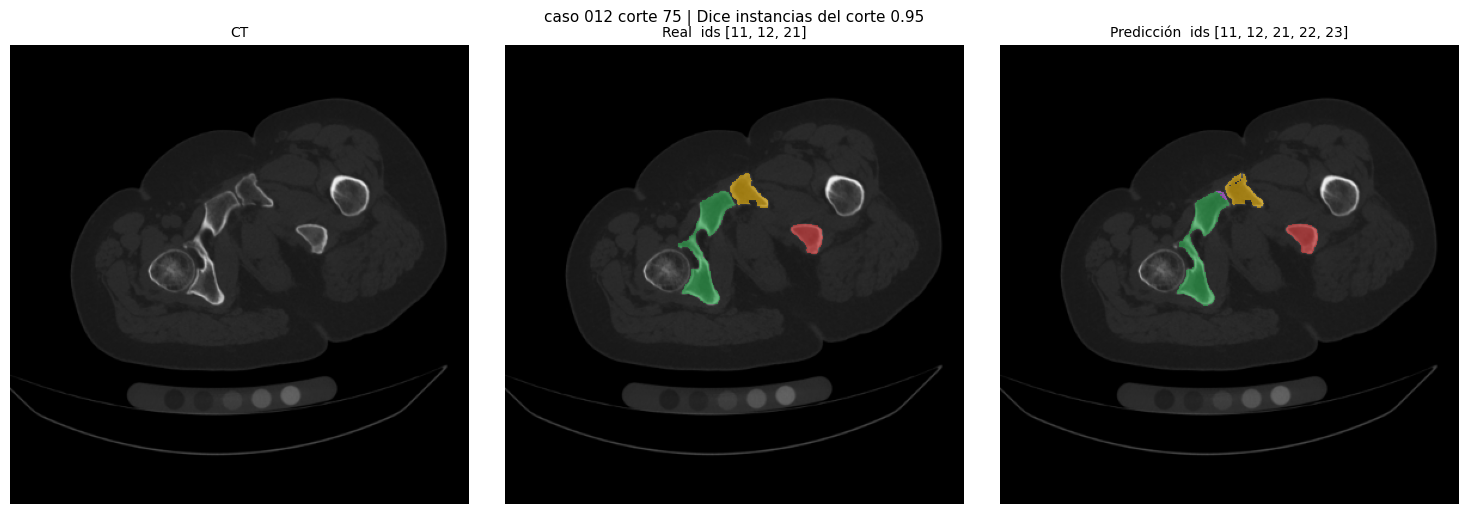

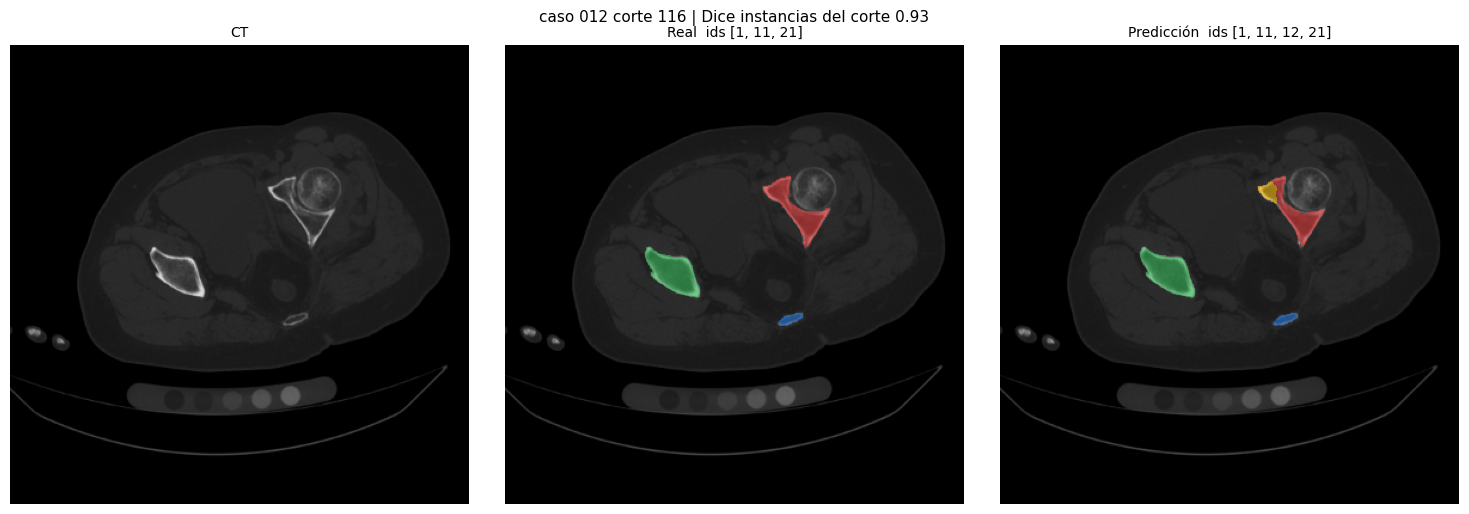

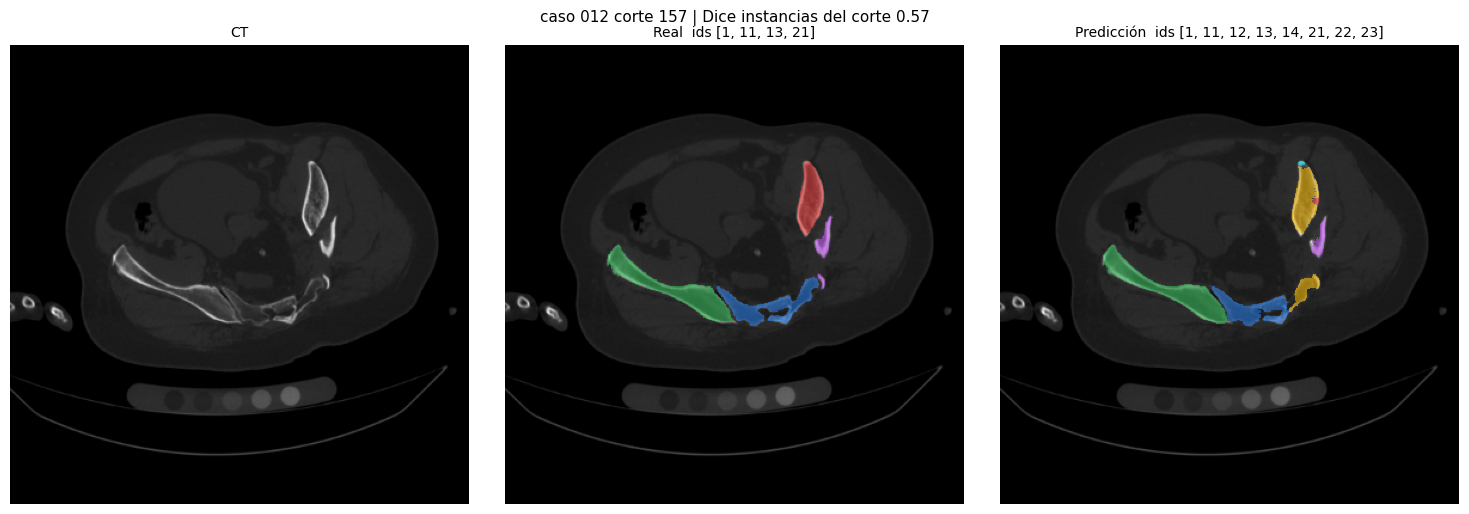

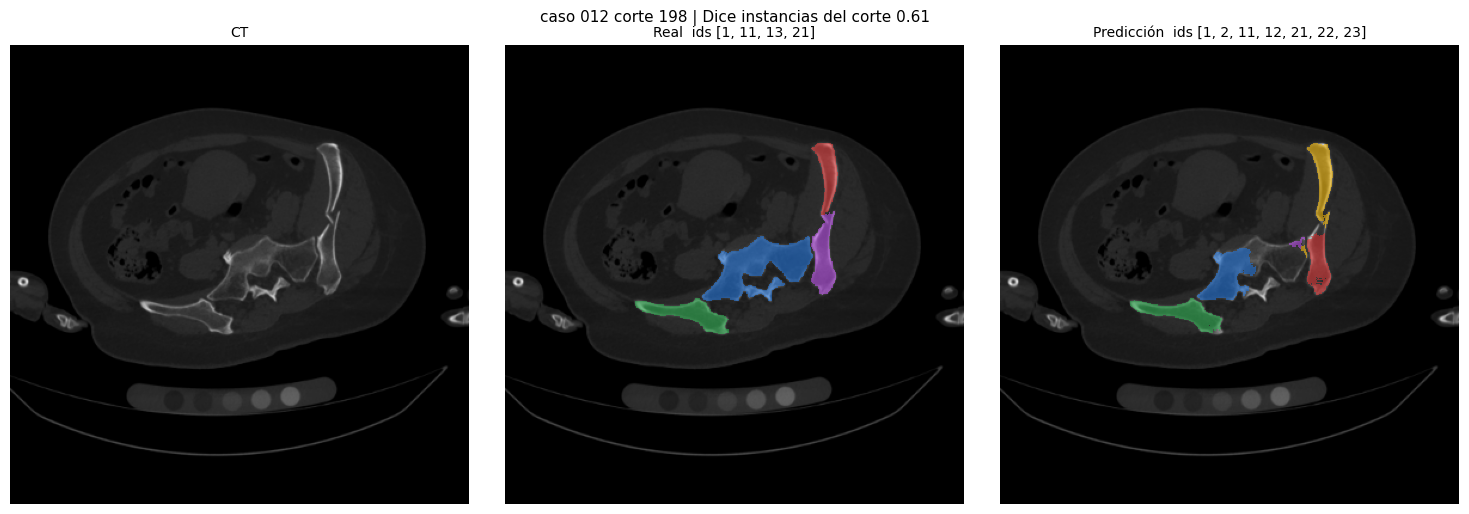

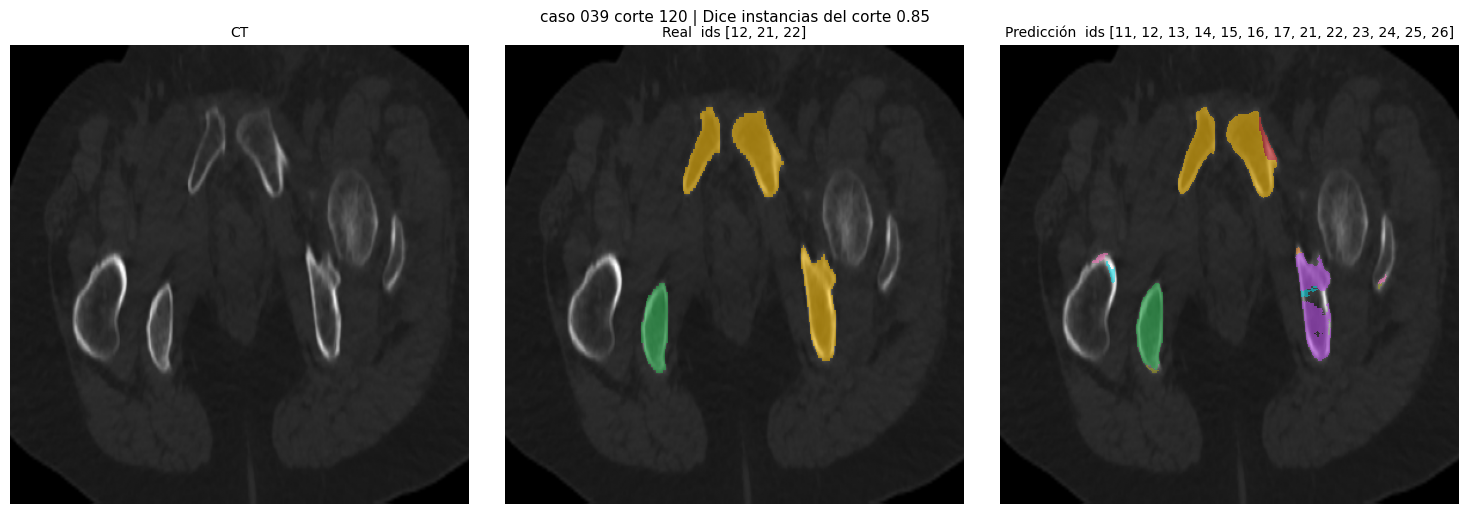

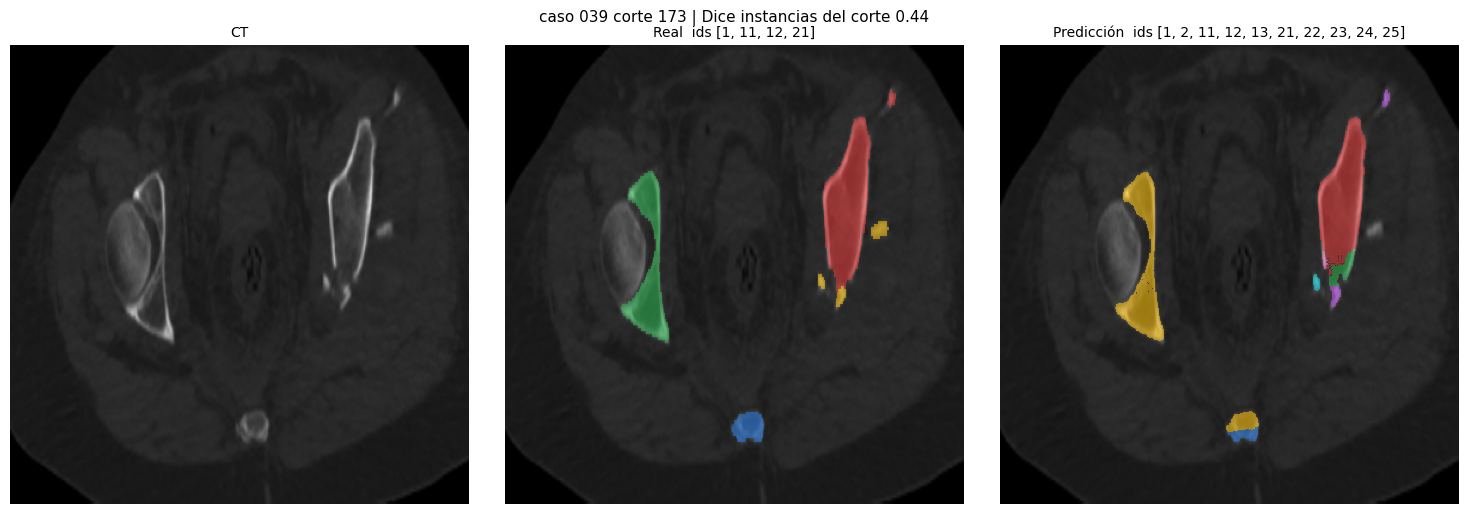

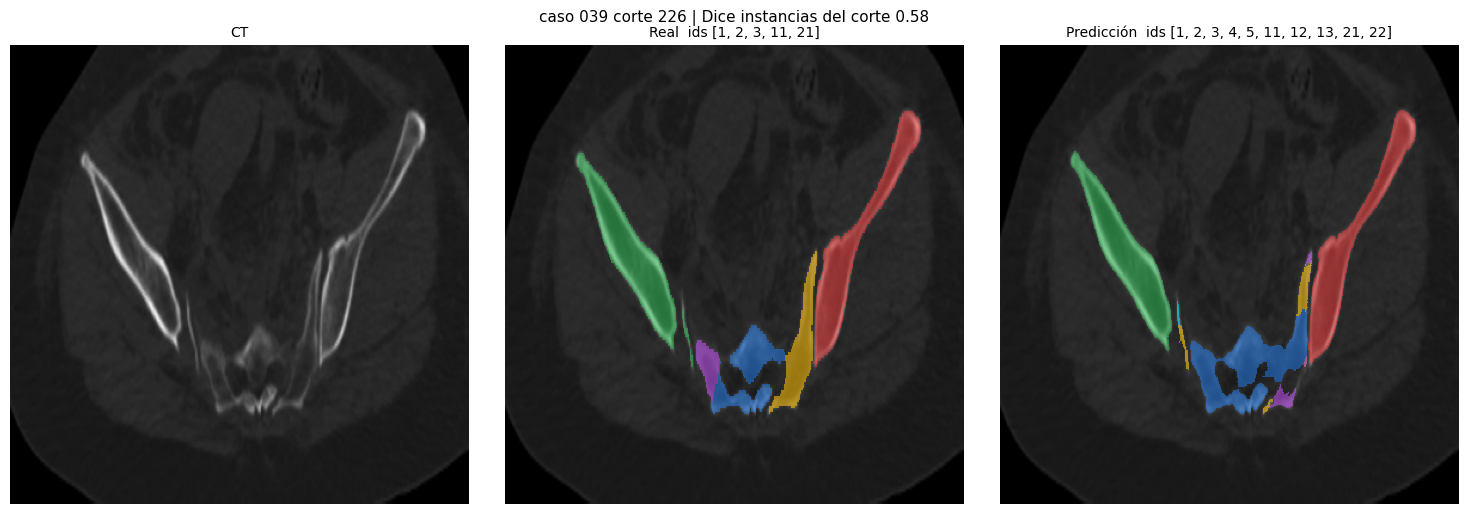

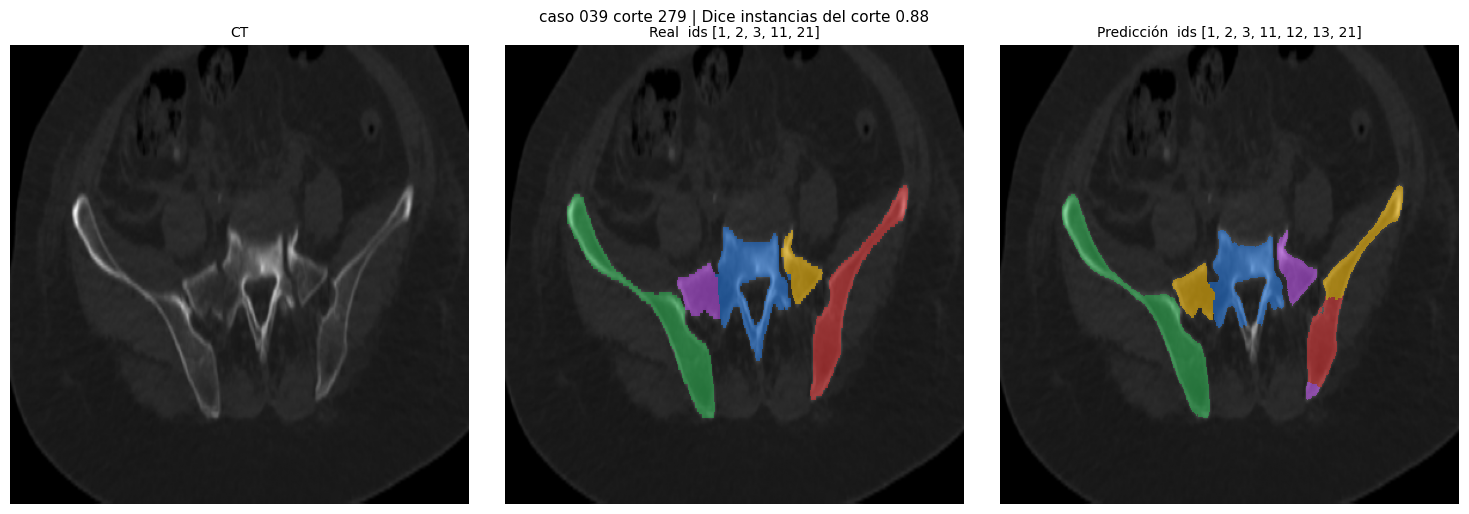

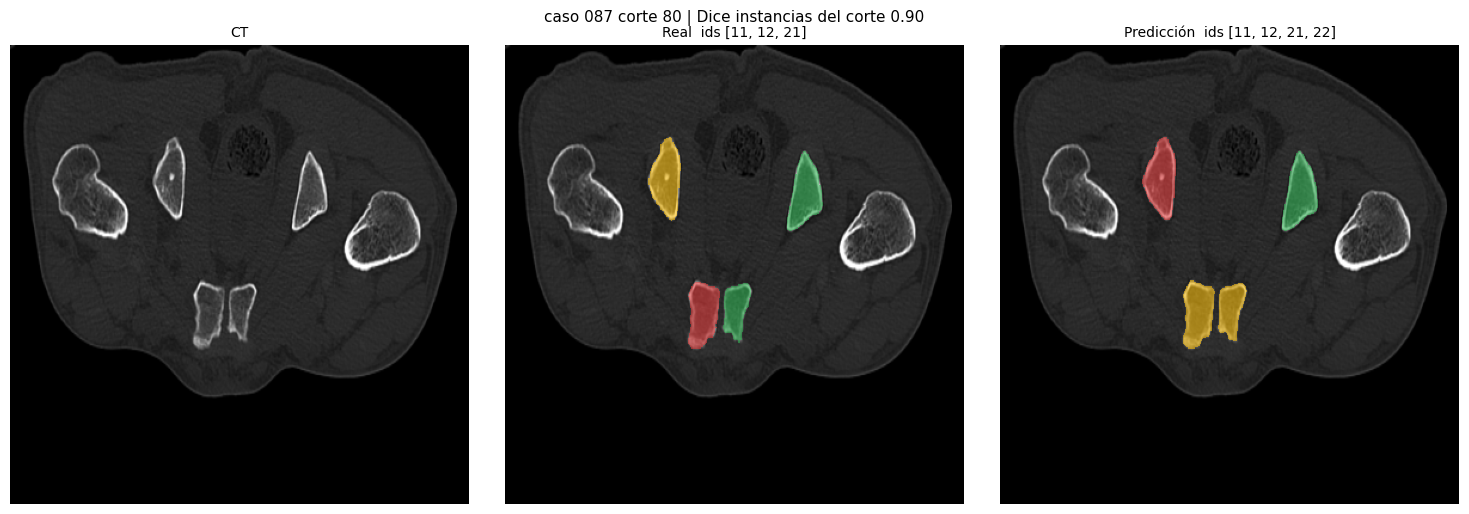

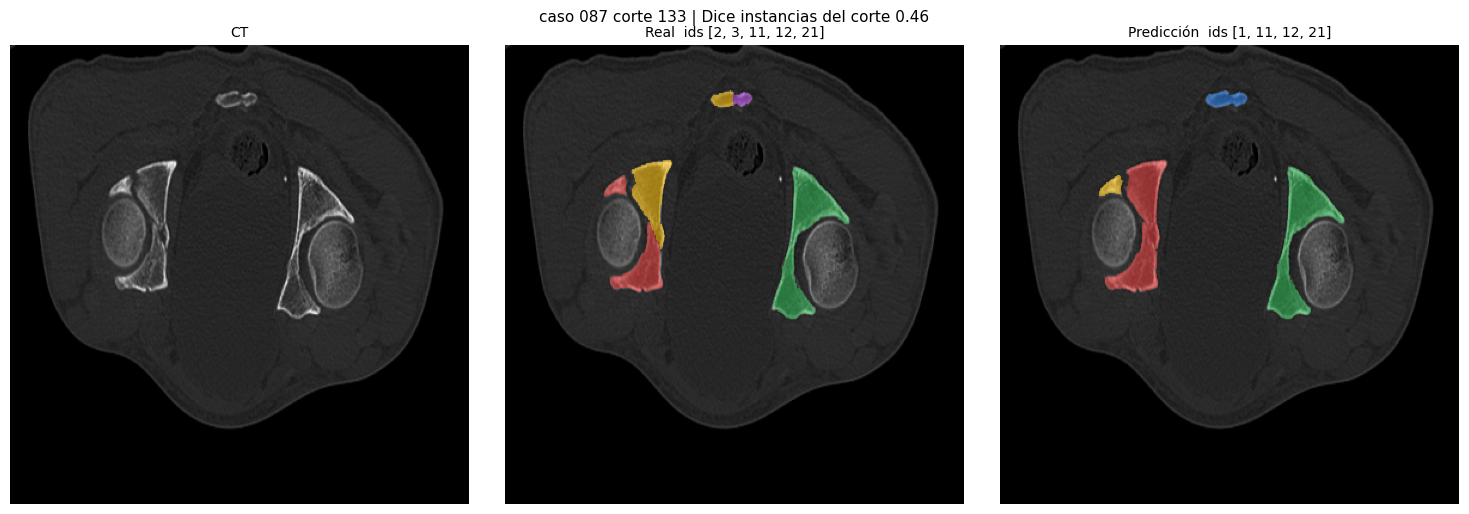

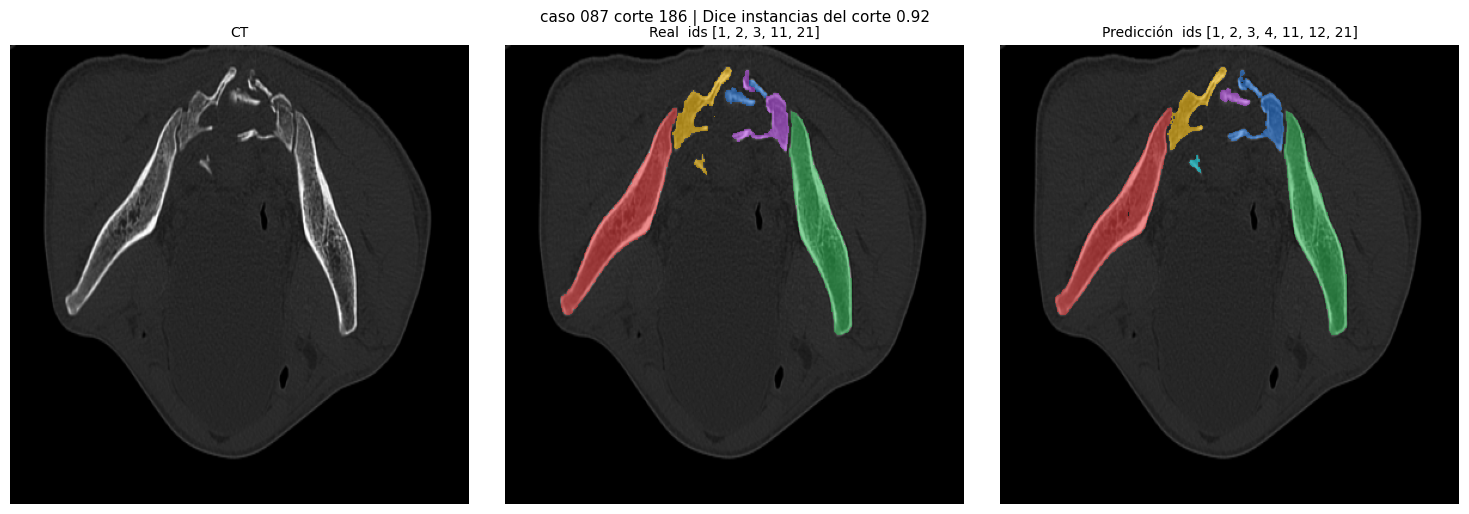

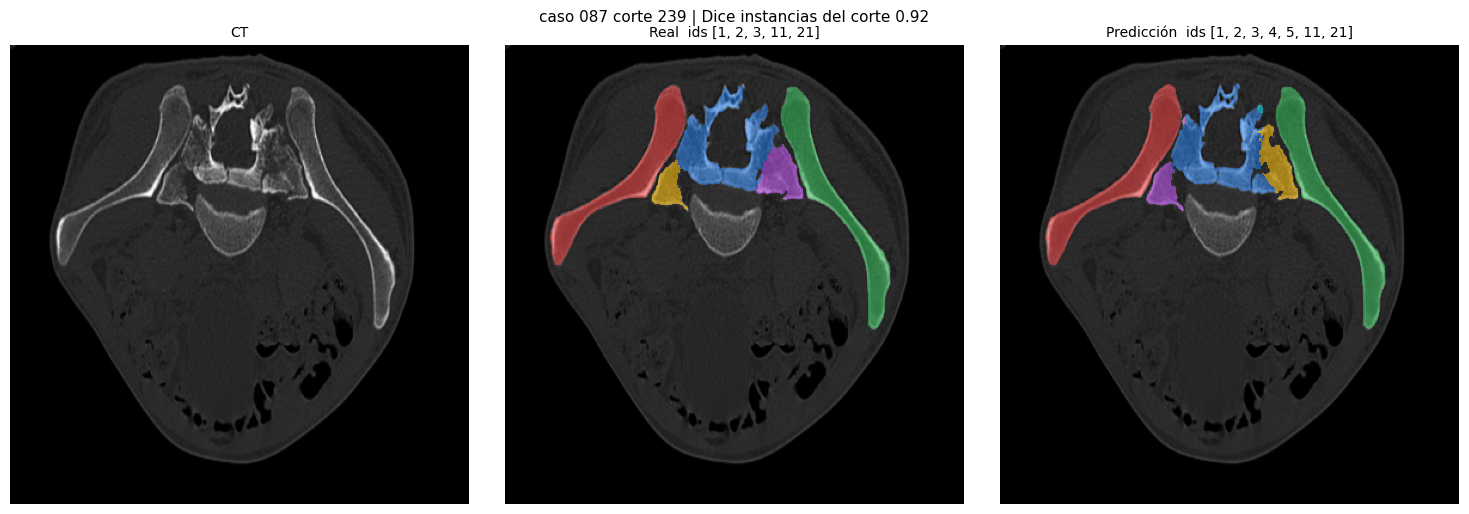

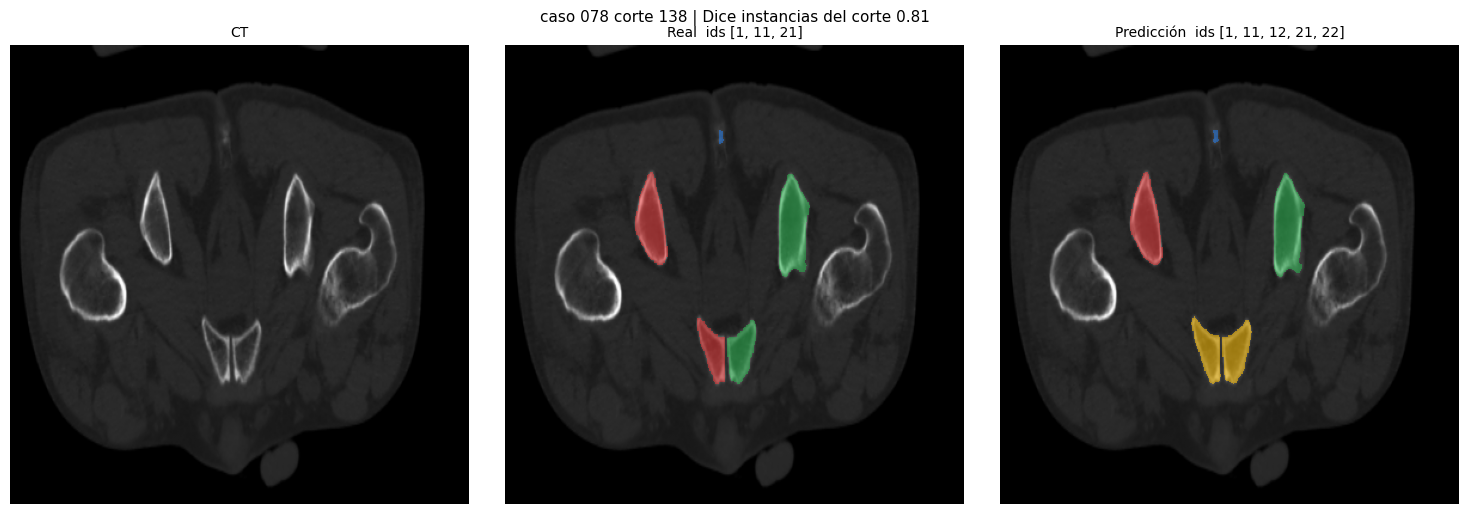

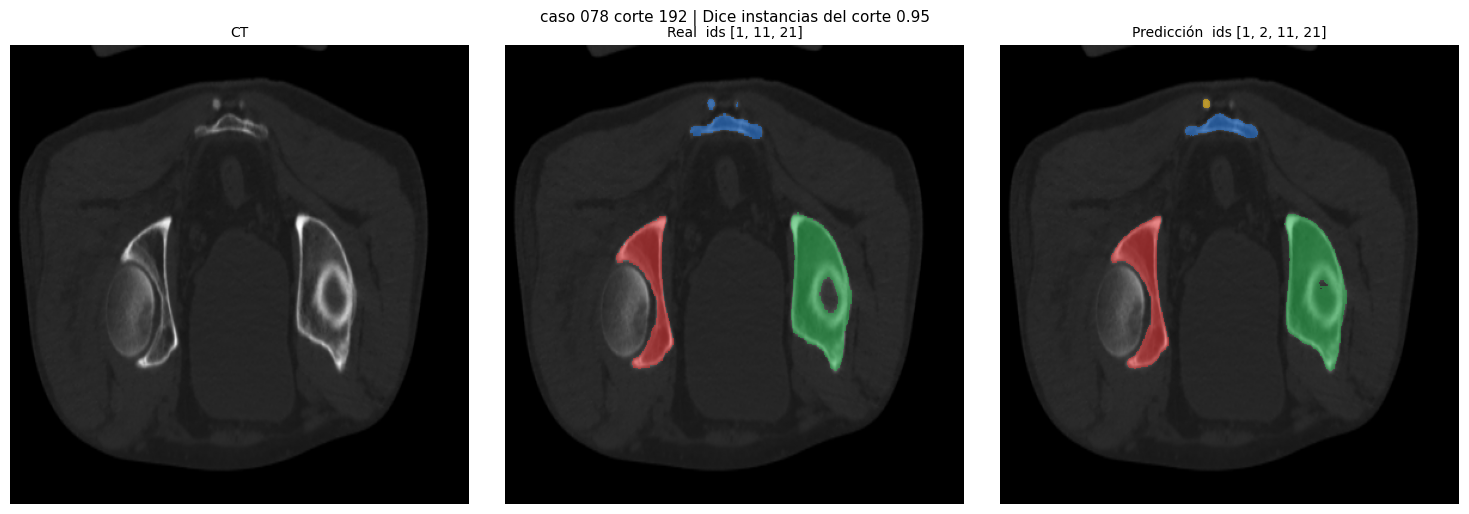

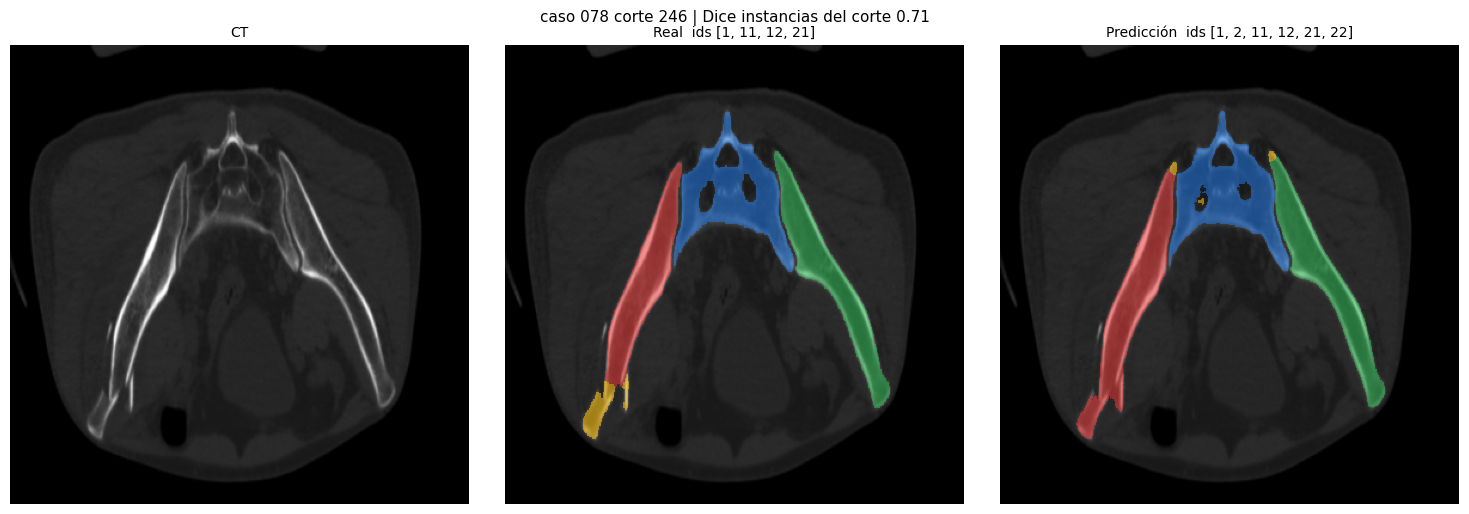

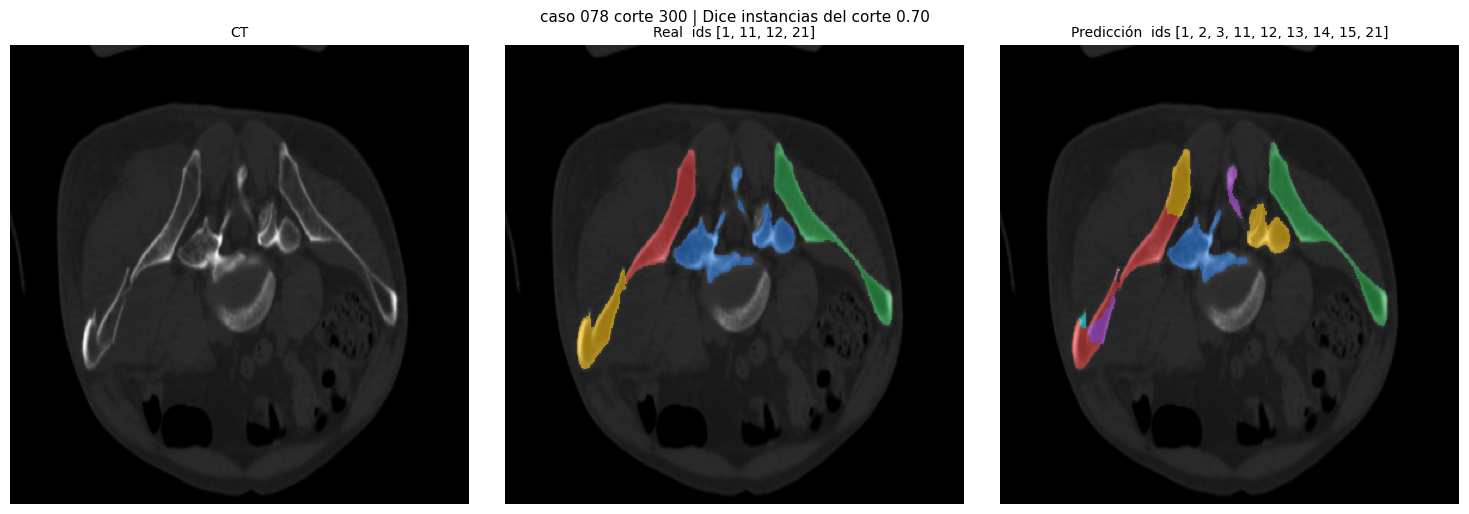

In [4]:
CASO = "012"
for c in CASOS:                     # cuatro cortes de cada caso; sube n para ver más
    cd.mosaico(datos[c]["images"], datos[c]["labels"], pred[c], f"caso {c}", n=4)
    plt.show()

In [5]:
# Deslizador para recorrer el volumen (necesita ipywidgets y el notebook abierto en Jupyter/Colab/VS Code).
# En ejecución por lotes se salta con la variable de entorno SIN_DESLIZADOR=1.
if os.environ.get("SIN_DESLIZADOR"):
    print("deslizador omitido en la ejecución por lotes")
else:
    try:
        from ipywidgets import interact, IntSlider, Dropdown

        def ver(caso, z):
            cd.mostrar(datos[caso]["images"], datos[caso]["labels"], pred[caso], z, f"caso {caso}")
            plt.show()

        interact(ver, caso=Dropdown(options=CASOS, value=CASO),
                 z=IntSlider(min=0, max=max(len(datos[c]["images"]) for c in CASOS) - 1, value=120, continuous_update=False))
    except ImportError:
        print("pip install ipywidgets para el deslizador; mientras tanto usa la celda siguiente")

deslizador omitido en la ejecución por lotes


012 peores cortes (z, Dice): [(34, 0.0), (233, 0.03), (236, 0.04), (234, 0.05), (235, 0.07), (215, 0.18)]
039 peores cortes (z, Dice): [(98, 0.3), (99, 0.32), (100, 0.33), (171, 0.37), (170, 0.37), (139, 0.37)]
087 peores cortes (z, Dice): [(291, 0.0), (292, 0.0), (290, 0.45), (133, 0.46), (134, 0.46), (132, 0.46)]
078 peores cortes (z, Dice): [(353, 0.34), (342, 0.36), (341, 0.37), (343, 0.37), (344, 0.37), (345, 0.39)]


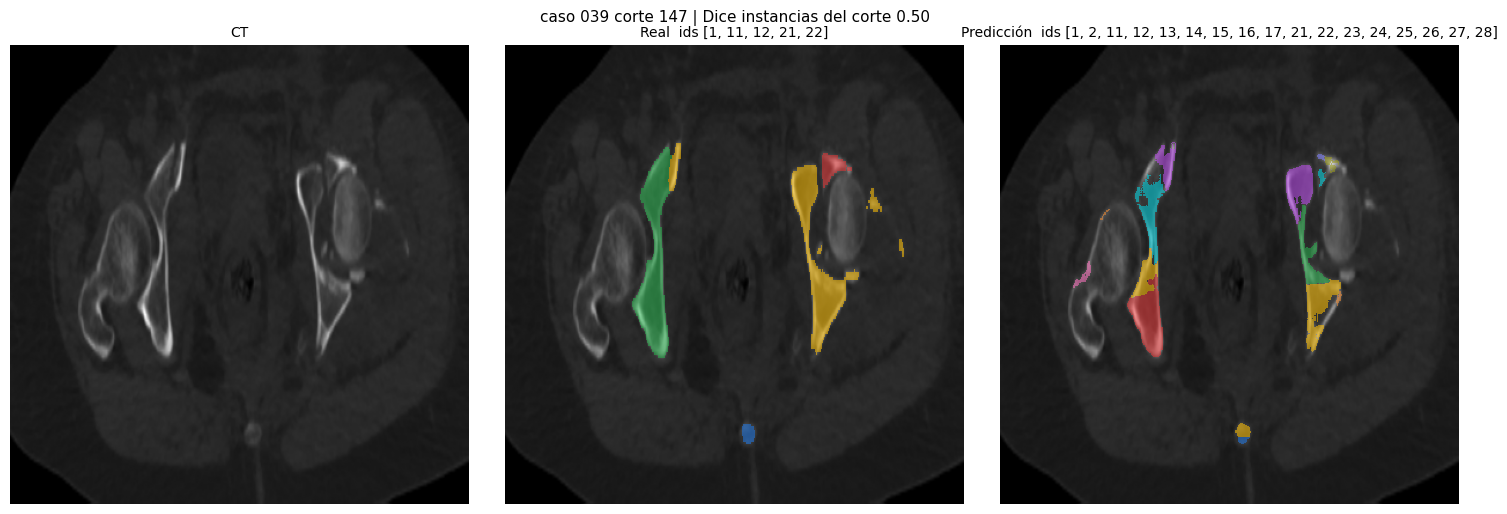

In [6]:
# Un corte concreto. Los peores cortes de cada caso:
for c in CASOS:
    print(c, "peores cortes (z, Dice):", [(z, round(d, 2)) for z, d in sorted(met[c]["por_corte"], key=lambda p: p[1])[:6]])

cd.mostrar(datos["039"]["images"], datos["039"]["labels"], pred["039"], 147, "caso 039")
plt.show()

## 4. Dice de instancias a lo largo del volumen

La línea punteada es el objetivo (0.85). Sirve para ver si un caso falla en todo el volumen o
solo en una zona (por ejemplo el acetábulo, donde están las fracturas conminutas).

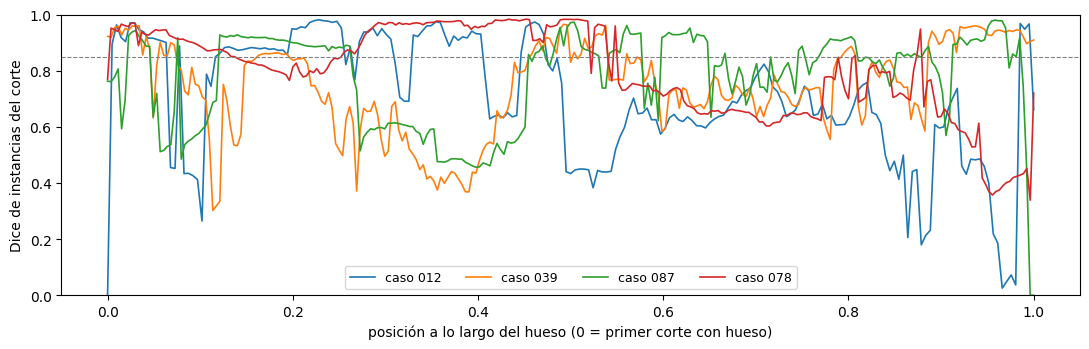

In [7]:
cd.curva_por_corte({f"caso {c}": met[c] for c in CASOS})
plt.show()

## 5. ¿Y si se reorienta antes de entrar al modelo?

### 5a. Los casos guardados girados 180° (por cabecera)

Se gira el caso a la orientación común y se vuelve a predecir **con el mismo modelo**. Este
modelo se entrenó viendo las dos orientaciones mezcladas, así que no se espera un salto aquí:
la ganancia de la orientación canónica viene de **reentrenar** con todos los casos orientados
igual (experimento H4), porque entonces izquierda y derecha dejan de depender de adivinar la
orientación del corte.

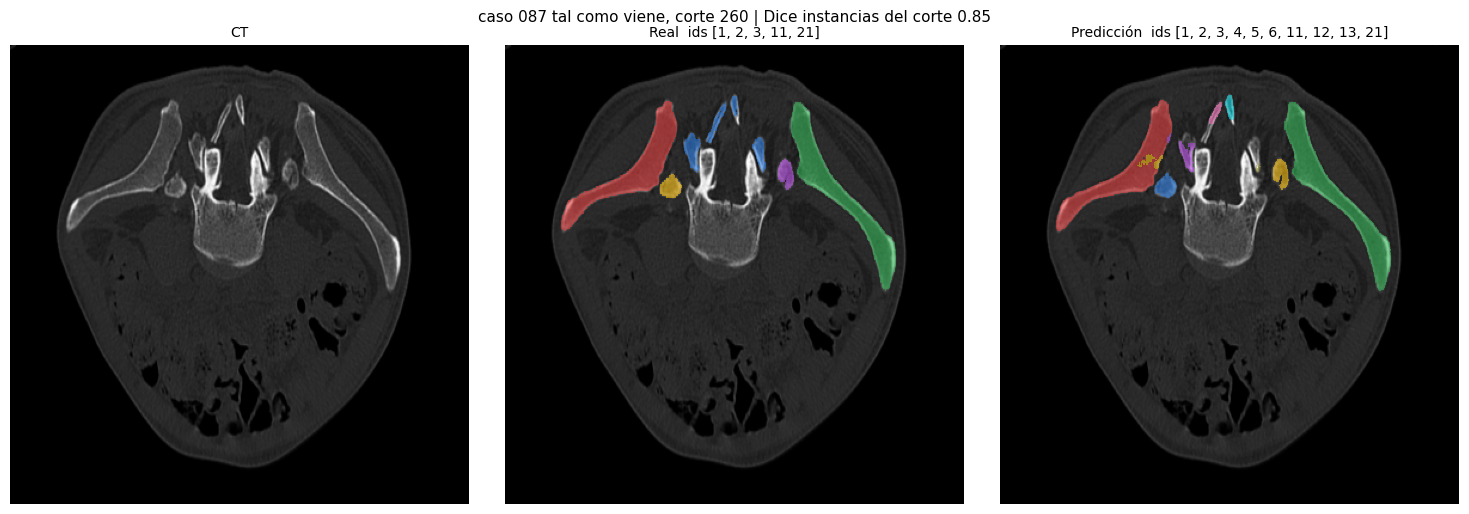

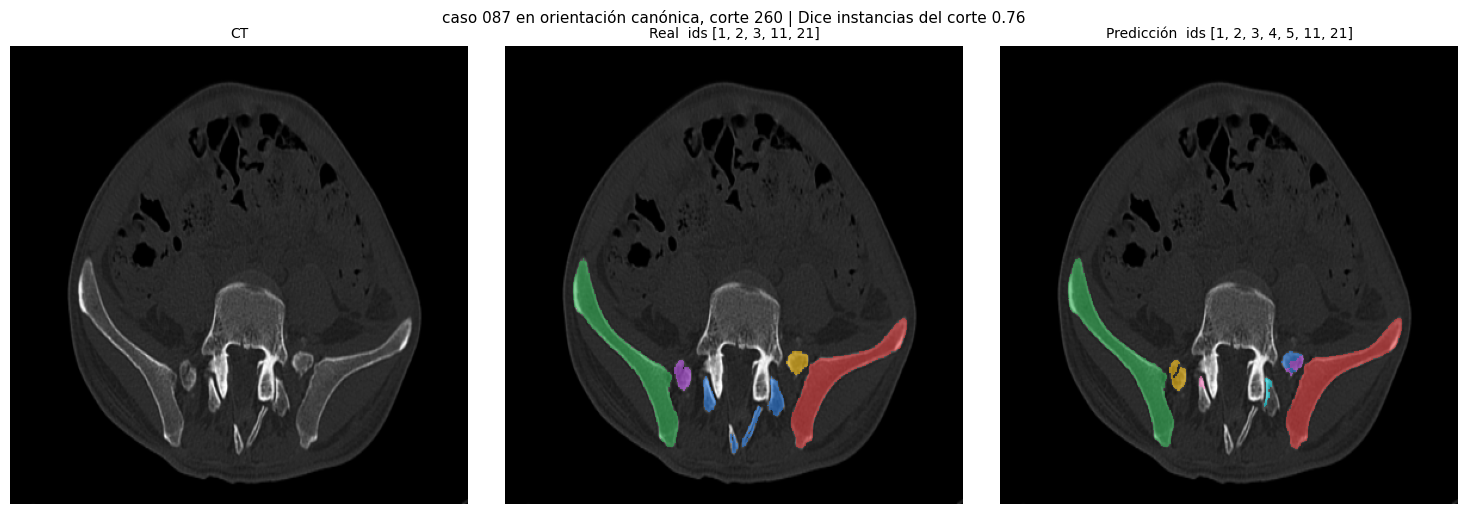

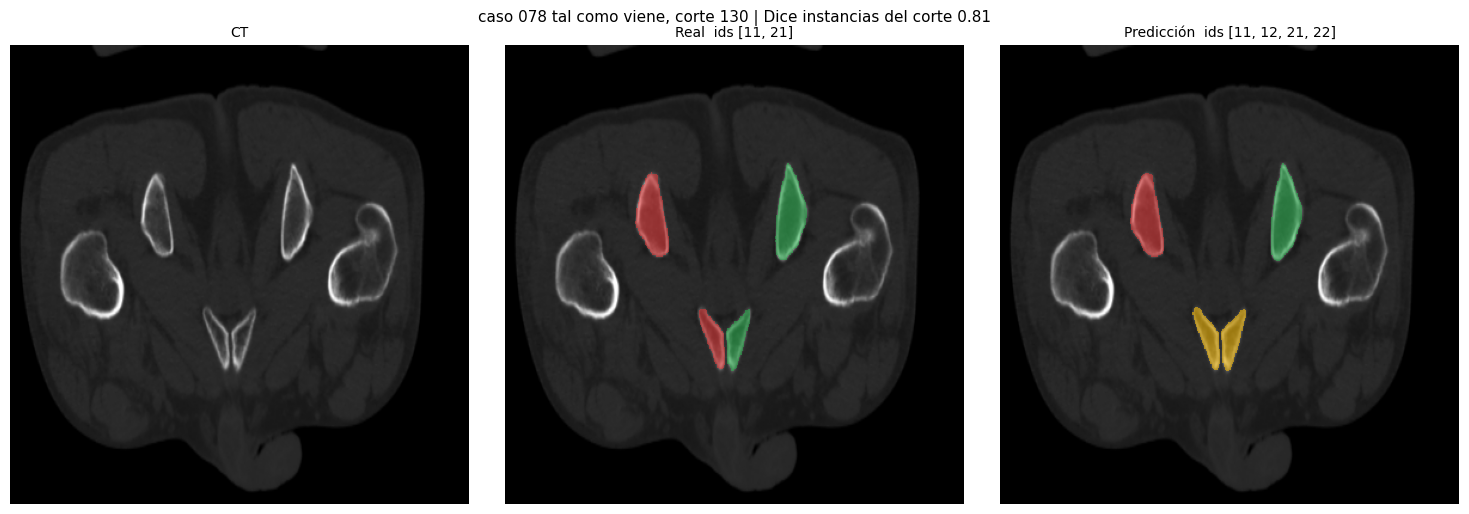

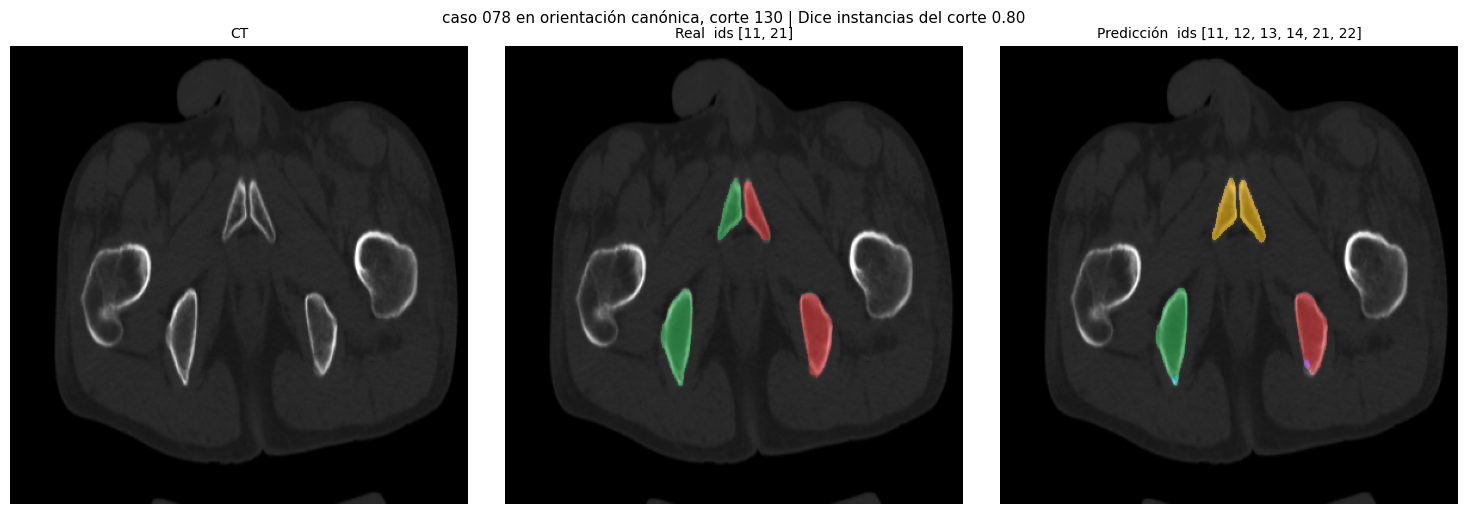

,caso,tal como viene,girado 180° (canónico)
0,087,0.768,0.770
1,078,0.789,0.808


In [8]:
filas = []
for c in CASOS:
    if c not in LPI_CASES:
        continue
    im, lb = to_canonical(datos[c]["images"], c), to_canonical(datos[c]["labels"], c)
    p = cd.predecir(modelo, im, device)
    m = cd.metricas(p, lb)["resumen"]
    filas.append({"caso": c, "tal como viene": met[c]["resumen"]["dice_instancias"], "girado 180° (canónico)": m["dice_instancias"]})
    z = sorted(met[c]["por_corte"], key=lambda q: q[1])[len(met[c]["por_corte"]) // 2][0]
    cd.mostrar(datos[c]["images"], datos[c]["labels"], pred[c], z, f"caso {c} tal como viene,")
    cd.mostrar(im, lb, p, z, f"caso {c} en orientación canónica,")
    plt.show()
pd.DataFrame(filas)

### 5b. Un paciente girado de verdad (caso 012)

La cabecera del 012 es la normal (RAI): aquí no hay metadato que corregir, el paciente estaba
acostado de lado. Dos pruebas:

1. **Barrido**: se gira el volumen varios ángulos y se mide el Dice con cada uno. Si hay un
   ángulo con el que el modelo acierta, el problema es la orientación y no la calidad de la imagen.
2. **Estimación automática**: con una primera predicción se mira hacia dónde queda el sacro
   respecto a los coxales (en un paciente bien colocado queda abajo) y se gira lo necesario. Solo
   usa "sacro contra coxales", no izquierda/derecha, que es justo lo que falla.

giro  -135°: instancias 0.090 | otra región 54.2 %


giro   -90°: instancias 0.080 | otra región 50.4 %


giro   -45°: instancias 0.831 | otra región 1.2 %


giro     0°: instancias 0.690 | otra región 14.0 %


giro    45°: instancias 0.028 | otra región 58.1 %


giro    90°: instancias 0.103 | otra región 49.4 %


giro   135°: instancias 0.754 | otra región 10.4 %


giro   180°: instancias 0.442 | otra región 31.3 %


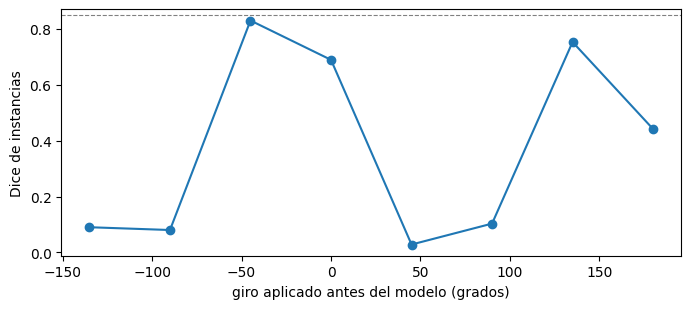

,giro,dice_instancias,dice_primario,dice_secundario,hueso_tomado_por_otra_region_%
0,-135,0.090,0.099,0.059,54.2
1,-90,0.080,0.083,0.071,50.4
2,-45,0.831,0.878,0.686,1.2
3,0,0.690,0.730,0.561,14.0
4,45,0.028,0.027,0.033,58.1
5,90,0.103,0.092,0.137,49.4
6,135,0.754,0.760,0.738,10.4
7,180,0.442,0.435,0.465,31.3


In [9]:
CASO_GIRO = "012"
im, lb = datos[CASO_GIRO]["images"], datos[CASO_GIRO]["labels"]
barrido = pd.DataFrame(cd.barrido_de_giros(modelo, device, im, lb, angulos=(-135, -90, -45, 0, 45, 90, 135, 180), paso=6))
ax = barrido.plot(x="giro", y=["dice_instancias"], marker="o", figsize=(8, 3.2), legend=False)
ax.axhline(0.85, color="gray", ls="--", lw=0.8); ax.set_xlabel("giro aplicado antes del modelo (grados)"); ax.set_ylabel("Dice de instancias")
plt.show()
barrido[["giro", "dice_instancias", "dice_primario", "dice_secundario", "hueso_tomado_por_otra_region_%"]]

ángulo del sacro respecto a los coxales (0 = abajo, lo normal):


  caso 012: predicción     7.5°   etiqueta real    25.8°


  caso 039: predicción    11.1°   etiqueta real     9.8°


  caso 087: predicción   178.7°   etiqueta real   178.6°


  caso 078: predicción   178.4°   etiqueta real   178.4°



giro estimado para el caso 012: -7.5°


,tal como viene,alineado automáticamente
dice_sacro,0.756,0.948
dice_coxal izq.,0.763,0.954
dice_coxal der.,0.832,0.968
hueso_tomado_por_otra_region_%,13.700,0.700
hueso_predicho_como_fondo_%,10.400,2.600
dice_instancias,0.692,0.774
dice_primario,0.729,0.868
dice_secundario,0.574,0.474


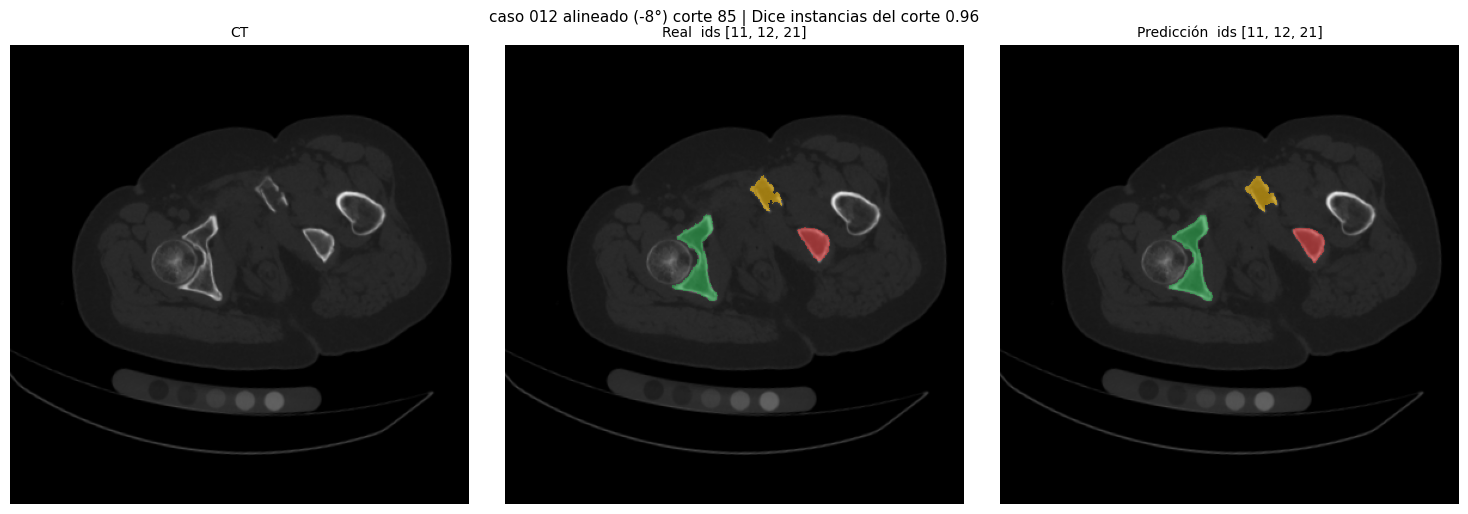

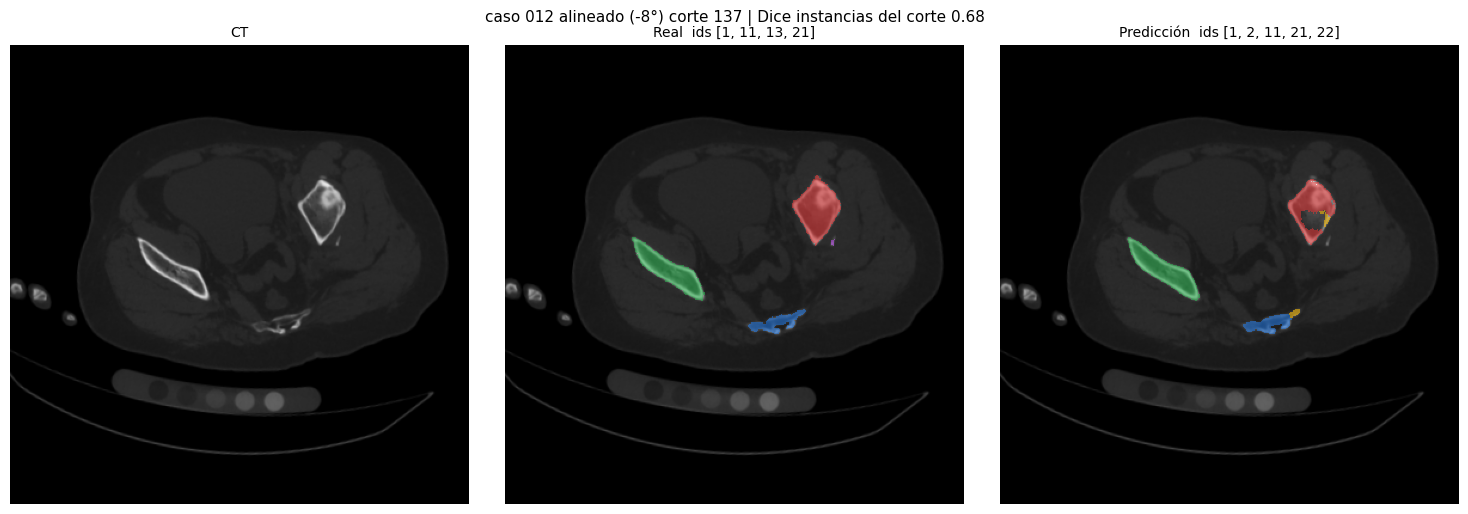

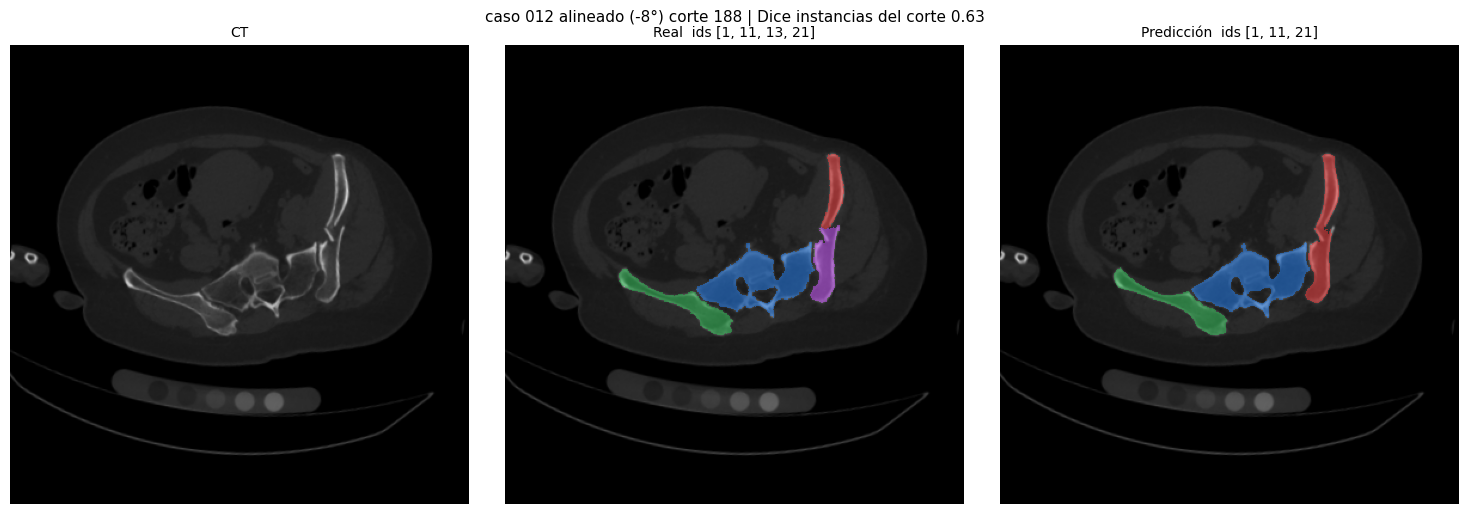

In [10]:
print("ángulo del sacro respecto a los coxales (0 = abajo, lo normal):")
for c in CASOS:
    print(f"  caso {c}: predicción {cd.angulo_del_sacro(pred[c]['semantica']):7.1f}°   etiqueta real {cd.angulo_del_sacro(cd.semantic_from_labels(datos[c]['labels'])):7.1f}°")

giro = cd.estimar_giro(pred[CASO_GIRO]["semantica"])
print(f"\ngiro estimado para el caso {CASO_GIRO}: {giro:.1f}°")
im2, lb2 = cd.girar(im, lb, giro)
p2 = cd.predecir(modelo, im2, device)
m2 = cd.metricas(p2, lb2)
display(pd.DataFrame({"tal como viene": met[CASO_GIRO]["resumen"], "alineado automáticamente": m2["resumen"]}))
cd.mosaico(im2, lb2, p2, f"caso {CASO_GIRO} alineado ({giro:.0f}°)", n=3)
plt.show()

## 6. Qué opciones hay

| Situación | Qué se puede hacer | Estado |
|---|---|---|
| 34 casos guardados girados 180° | Preprocesamiento determinista: leer la cabecera y dejarlos todos en la misma orientación (`src/orientacion.py`, bandera `--canonical`) | Experimento H4, hay que reentrenar |
| Paciente acostado de lado (012) | (a) Que la red lo aprenda: aumento con rotaciones al entrenar. (b) Alinear antes de predecir: primera pasada, estimar el ángulo del sacro, girar, segunda pasada | (a) experimento H3; (b) prototipo en la sección 5b |
| Volumen de pocas filas y espaciado grueso (039) | Conservar la proporción real (`--mode pad`) y simular baja resolución al entrenar | Experimentos H2 y H3 |
| Dónde se parte el hueso (087, 078) | No es de orientación: más resolución (512) y coherencia entre cortes | Caché a 512 construido |

**Apuntes propios:**

- 
